In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import taichi as ti

from utils import (
    init_population,
    evaluate_population_dataset,
    save_genome,
    write_csv_rows,
    run_single_input_cpu,
    plot_board,
    plot_trajectory_strip,
    TaichiGoLBatch,
)

# -------------------------
# Paths
# -------------------------
PROJECT_DIR = Path.cwd()
RUN_DIR = PROJECT_DIR / "runs"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(PROJECT_DIR)
print(RUN_DIR)

# -------------------------
# Hyperparameters
# -------------------------
P = 5_000
Lp = 16
Ls = 6
Le = 40
s = 2

n_gliders = 2
p_active_on = 0.95

T_max = 600
generations = 8

k_invalid = 1.6
k_interact = 0.6
k_exact = 0.1
k_multi = 0.01

task_fn = lambda x: x+2#np.where(x % 2 == 0, x, x - 1)

xs_train = np.arange(0, 10, dtype=np.int32)
ys_train = task_fn(xs_train).astype(np.float32)

print("x_train:", xs_train)
print("y_train:", ys_train)

dataset_size = len(xs_train)
evals_per_gen = P * dataset_size


print(
    {
        "P": P,
        "Lp": Lp,
        "Ls": Ls,
        "Le": Le,
        "s": s,
        "n_gliders": n_gliders,
        "p_active_on": p_active_on,
        "T_max": T_max,
        "generations": generations,
        "k_invalid": k_invalid,
        "k_interact": k_interact,
        "k_exact": k_exact,
        "k_multi": k_multi,
        "xs_train": xs_train.tolist(),
        "ys_train": ys_train.tolist(),
        "dataset_size": dataset_size,
        "evals_per_gen": evals_per_gen,
    }
)

# -------------------------
# Taichi simulator (training path unchanged)
# -------------------------
ti.init(arch=ti.cuda)
simulator = TaichiGoLBatch(
    B=P,
    Lp=Lp,
    Ls=Ls,
    Le=Le,
    n_gliders=n_gliders,
    s=s,
)

# warmup
warm_pos, warm_act = init_population(
    pop_size=P,
    n_gliders=n_gliders,
    Lp=Lp,
    p_active_on=p_active_on,
)
_ = evaluate_population_dataset(
    simulator=simulator,
    positions=warm_pos,
    active=warm_act,
    xs=[0],
    ys=np.array([1.0], dtype=np.float32),
    T_max=1,
    k_invalid=k_invalid,
    k_interact=k_interact,
    k_exact=k_exact,
    k_multi=k_multi,
)

# -------------------------
# Random search (training path unchanged)
# -------------------------
log_header = [
    "gen",
    "best_loss",
    "best_mae",
    "best_invalid",
    "best_exact",
    "best_interact",
    "best_multi",
    "evals_this_gen",
    "evals_cum",
    "init_time",
    "encoding_time",
    "sim_time",
    "decoding_time",
    "total_eval_time",
]


[Taichi] version 1.7.4, llvm 15.0.1, commit b4b956fd, win, python 3.12.10


c:\Users\Admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\taichi\tools\image.py:64: SyntaxWarning: invalid escape sequence '\['
  if dtype is float-type (`ti.f16`, `ti.f32`, `np.float32` etc), **the value of each pixel should be float between \[0.0, 1.0\]**. Otherwise `ti.tools.imwrite` will first clip them into \[0.0, 1.0\]\


c:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm
c:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm\runs
x_train: [0 1 2 3 4 5 6 7 8 9]
y_train: [ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
{'P': 5000, 'Lp': 16, 'Ls': 6, 'Le': 40, 's': 2, 'n_gliders': 2, 'p_active_on': 0.95, 'T_max': 600, 'generations': 8, 'k_invalid': 1.6, 'k_interact': 0.6, 'k_exact': 0.1, 'k_multi': 0.01, 'xs_train': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'ys_train': [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0], 'dataset_size': 10, 'evals_per_gen': 50000}
[Taichi] Starting on arch=cuda


c:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm\utils.py:395: SyntaxWarning: You are unrolling more than
                        32 iterations, so the compile time may be extremely long.
                        You can use a non-static for loop if you want to decrease the compile time.
                        You can disable this warning by setting ti.init(unrolling_limit=0).
  for di, dj in ti.static(ti.ndrange(6, 6)):


In [2]:

all_log_rows = []

best_overall_positions = None
best_overall_active = None
best_overall_metrics = None
best_overall_loss = np.inf
best_overall_gen = -1

for gen in range(1, generations + 1):
    t0 = time.perf_counter()
    positions, active = init_population(
        pop_size=P,
        n_gliders=n_gliders,
        Lp=Lp,
        p_active_on=p_active_on,
    )
    t1 = time.perf_counter()

    metrics, times = evaluate_population_dataset(
        simulator=simulator,
        positions=positions,
        active=active,
        xs=xs_train,
        ys=ys_train,
        T_max=T_max,
        k_invalid=k_invalid,
        k_interact=k_interact,
        k_exact=k_exact,
        k_multi=k_multi,
    )
    t2 = time.perf_counter()

    best_idx = int(np.argmin(metrics["loss"]))
    best_loss = float(metrics["loss"][best_idx])

    if best_loss < best_overall_loss:
        best_overall_loss = best_loss
        best_overall_positions = positions[best_idx].copy()
        best_overall_active = active[best_idx].copy()
        best_overall_gen = gen
        best_overall_metrics = {
            "loss": float(metrics["loss"][best_idx]),
            "mae": float(metrics["mae"][best_idx]),
            "invalid": float(metrics["invalid"][best_idx]),
            "exact": float(metrics["exact"][best_idx]),
            "interact": float(metrics["interact"][best_idx]),
            "multi": float(metrics["multi"][best_idx]),
        }

    evals_cum = gen * evals_per_gen

    row = [
        gen,
        float(metrics["loss"][best_idx]),
        float(metrics["mae"][best_idx]),
        float(metrics["invalid"][best_idx]),
        float(metrics["exact"][best_idx]),
        float(metrics["interact"][best_idx]),
        float(metrics["multi"][best_idx]),
        int(evals_per_gen),
        int(evals_cum),
        t1 - t0,
        times["encoding"],
        times["sim"],
        times["decoding"],
        t2 - t1,
    ]
    all_log_rows.append(row)

    print(
        f"gen={gen:4d}  "
        f"best_loss={row[1]:.4f}  "
        f"best_mae={row[2]:.4f}  "
        f"best_invalid={row[3]:.4f}  "
        f"best_exact={row[4]:.4f}  "
        f"best_interact={row[5]:.4f}  "
        f"best_multi={row[6]:.4f}  "
        f"evals_gen={row[7]:,d}  "
        f"evals_cum={row[8]:,d}  "
        f"init={row[9]:.3f}s  "
        f"encoding={row[10]:.3f}s  "
        f"sim={row[11]:.3f}s  "
        f"decoding={row[12]:.3f}s  "
        f"eval_total={row[13]:.3f}s"
    )

print("\n=== overall best ===")
print("best_overall_gen:", best_overall_gen)
print("best_overall_metrics:", best_overall_metrics)

# -------------------------
# Save
# -------------------------
log_path = RUN_DIR / "random_search_log.csv"
write_csv_rows(log_path, log_header, all_log_rows)

config = {
    "P": P,
    "Lp": Lp,
    "Ls": Ls,
    "Le": Le,
    "s": s,
    "n_gliders": n_gliders,
    "p_active_on": p_active_on,
    "T_max": T_max,
    "generations": generations,
    "k_invalid": k_invalid,
    "k_interact": k_interact,
    "k_exact": k_exact,
    "k_multi": k_multi,
    "xs_train": xs_train.tolist(),
    "ys_train": ys_train.tolist(),
    "dataset_size": dataset_size,
    "evals_per_gen": evals_per_gen,
    "best_overall_gen": best_overall_gen,
}

model_path = RUN_DIR / "best_random_genome.npz"
save_genome(
    path=model_path,
    positions=best_overall_positions,
    active=best_overall_active,
    metrics=best_overall_metrics,
    config=config,
    Lp=Lp,
)

print(log_path)
print(model_path)

gen=   1  best_loss=-0.7000  best_mae=0.0000  best_invalid=0.0000  best_exact=1.0000  best_interact=1.0000  best_multi=0.0000  evals_gen=50,000  evals_cum=50,000  init=0.000s  encoding=0.010s  sim=6.823s  decoding=0.044s  eval_total=6.882s
gen=   2  best_loss=-0.7000  best_mae=0.0000  best_invalid=0.0000  best_exact=1.0000  best_interact=1.0000  best_multi=0.0000  evals_gen=50,000  evals_cum=100,000  init=0.000s  encoding=0.010s  sim=6.828s  decoding=0.046s  eval_total=6.888s
gen=   3  best_loss=-0.7000  best_mae=0.0000  best_invalid=0.0000  best_exact=1.0000  best_interact=1.0000  best_multi=0.0000  evals_gen=50,000  evals_cum=150,000  init=0.000s  encoding=0.010s  sim=6.850s  decoding=0.048s  eval_total=6.911s
gen=   4  best_loss=-0.7000  best_mae=0.0000  best_invalid=0.0000  best_exact=1.0000  best_interact=1.0000  best_multi=0.0000  evals_gen=50,000  evals_cum=200,000  init=0.000s  encoding=0.010s  sim=6.846s  decoding=0.043s  eval_total=6.903s
gen=   5  best_loss=-0.7000  best_mae

{'x': 5, 'target': 7.0, 'pred': 7.0, 'exact': True, 'accuracy': 1.0, 'stable_end': True, 'interacted': True, 'chosen_block': (36, 25), 'n_valid_blocks': 1, 'valid_blocks': [(36, 25)], 'valid': True, 'steps_run': 104, 'n_extensions': 0, 'final_side': 62}


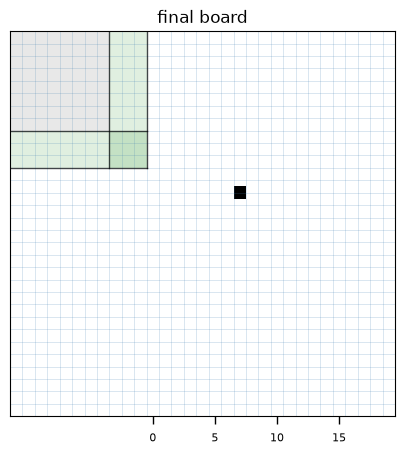

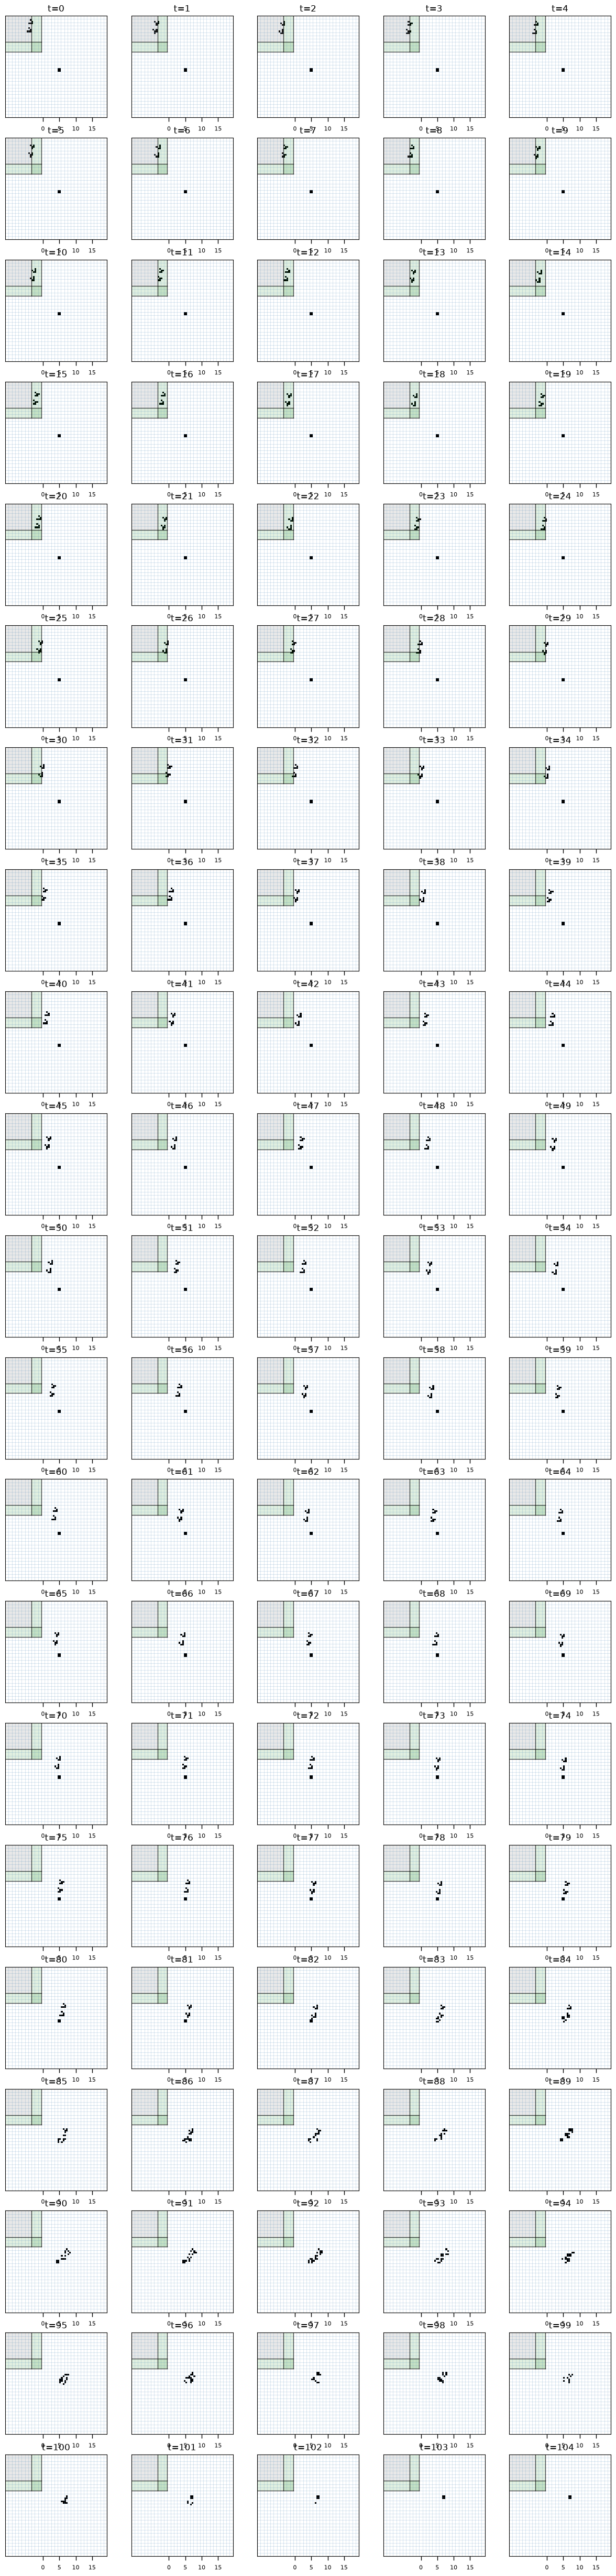

done


In [3]:

# -------------------------
# Inspect one input on CPU (new default eval mode: self-extending)
# -------------------------
final_inspect_x=5
target = float(task_fn(np.array([final_inspect_x], dtype=np.int32))[0])

result = run_single_input_cpu(
    positions=best_overall_positions,
    active=best_overall_active,
    x=final_inspect_x,
    target=target,
    Lp=Lp,
    Ls=Ls,
    Le=Le,
    T_max=T_max,
    s=s,
    growth=10,
    margin_trigger=3,
    plot=False,          # keep explicit plotting below
    store_frames=True,
)

print(
    {
        "x": final_inspect_x,
        "target": target,
        "pred": result["pred"],
        "exact": result["exact"],
        "accuracy": result["accuracy"],
        "stable_end": result["stable_end"],
        "interacted": result["interacted"],
        "chosen_block": result["chosen_block"],
        "n_valid_blocks": result["n_valid_blocks"],
        "valid_blocks": result["valid_blocks"],
        "valid": result["valid"],
        "steps_run": result["steps_run"],
        "n_extensions": result["n_extensions"],
        "final_side": result["final_side"],
    }
)

fig, ax = plot_board(
    result["final_board"],
    title="final board",
    Lp=Lp,
    Ls=Ls,
    s=s,
)
plt.show()

fig, axes = plot_trajectory_strip(
    result["frames"],
    cols=5,
    figsize_per_panel=3,
    Lp=Lp,
    Ls=Ls,
    s=s,
)
plt.show()

print("done")

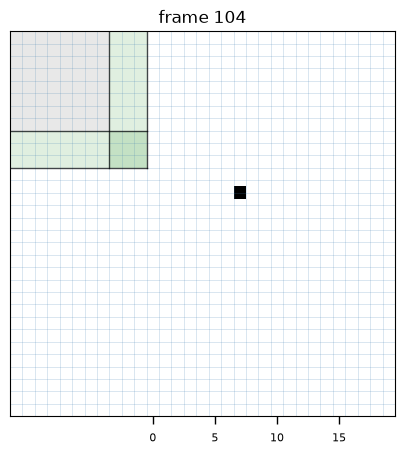

In [7]:
index = len(result["frames"]) - 1

i_board=result["frames"][index]

fig, ax = plot_board(
    i_board,
    title=f"frame {index}",
    Lp=Lp,
    Ls=Ls,
    s=s,
)
plt.show()

In [6]:
# -------------------------
# Large extrapolation eval: 0..100
# -------------------------
from utils import evaluate_genome_dataset_cpu

xs_test = np.arange(0, 103, dtype=np.int32)
ys_test = task_fn(xs_test).astype(np.float32)

summary, records = evaluate_genome_dataset_cpu(
    positions=best_overall_positions,
    active=best_overall_active,
    xs=xs_test,
    ys=ys_test,
    Lp=Lp,
    Ls=Ls,
    Le=Le,
    T_max=3000,          # large eval budget
    s=s,
    growth=10,
    margin_trigger=3,
    plot=False,          # keep False for large runs
    progress=True,       # minimal per-input progress print
)

print("\n=== large-dataset summary ===")
print(summary)

# Exact-rate convenience print
print(f"exact_rate = {summary['exact_rate']:.6f}")
print(f"valid_rate = {summary['valid_rate']:.6f}")
print(f"mae_valid  = {summary['mae_valid']}")

# Collect wrong or invalid examples
wrong_records = [
    r for r in records
    if (not r["valid"]) or (not r["exact"])
]

print(f"\nwrong_or_invalid_count = {len(wrong_records)} / {len(records)}")

# Show first few wrong examples
show_n = 30
if wrong_records:
    print(f"\nFirst {min(show_n, len(wrong_records))} wrong/invalid examples:")
    for r in wrong_records[:show_n]:
        print(
            {
                "x": r["x"],
                "target": r["target"],
                "pred": r["pred"],
                "exact": r["exact"],
                "valid": r["valid"],
                "stable_end": r["stable_end"],
                "n_extensions": r["n_extensions"],
                "final_side": r["final_side"],
                "steps_run": r["steps_run"],
                "n_valid_blocks": r["n_valid_blocks"],
            }
        )
else:
    print("No wrong or invalid examples.")

[1/103] x=0  target=2.0  pred=2.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=64
[2/103] x=1  target=3.0  pred=3.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=72
[3/103] x=2  target=4.0  pred=4.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=80
[4/103] x=3  target=5.0  pred=5.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=88
[5/103] x=4  target=6.0  pred=6.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=96
[6/103] x=5  target=7.0  pred=7.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=104
[7/103] x=6  target=8.0  pred=8.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=112
[8/103] x=7  target=9.0  pred=9.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=120
[9/103] x=8  target=10.0  pred=10.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=128
[10/103] x=9  target=11.0  pred=11.0  exact=True  valid=True  stable=True  ext=0  side=62  steps=136
[11/103] x=10  targe